# Exercise 2: Fine-tuning a Pretrained Model for Binary Text Classification

## Objective
Fine-tune a pretrained Transformer model to classify English movie
reviews into two sentiment classes: negative and positive.

## Workflow
1. Prepare the environment.
2. Load and inspect the dataset.
3. Load the pretrained model and tokenizer.
4. Tokenize the dataset.
5. Configure training arguments.
6. Fine-tune the model using Trainer.
7. Evaluate and save the model.

## Implementation
The leader implements and runs the complete notebook.
Other members review the code, outputs, and conclusions.


In [1]:
import sys
import torch
import transformers

print("Python:", sys.version)
print("Executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

d:\learn_DeepLearning\Lab3\.venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Executable: d:\learn_DeepLearning\Lab3\.venv311\Scripts\python.exe
PyTorch: 2.14.1+cpu
Transformers: 4.57.1


In [2]:
%pip install -q transformers datasets evaluate accelerate scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import torch
import transformers
import datasets
import evaluate
import accelerate
import sklearn

from transformers.utils import is_torch_available

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])

print("\nLibrary versions:")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Evaluate:", evaluate.__version__)
print("Accelerate:", accelerate.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nTransformers detects PyTorch:", is_torch_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python executable: d:\learn_DeepLearning\Lab3\.venv311\Scripts\python.exe
Python version: 3.11.9

Library versions:
PyTorch: 2.14.1+cpu
Transformers: 4.57.1
Datasets: 3.3.2
Evaluate: 0.4.6
Accelerate: 1.11.0
Scikit-learn: 1.9.1

Transformers detects PyTorch: True
Device: cpu


## 2. Load and Inspect the Dataset

This exercise uses the IMDB movie review dataset for binary
sentiment classification.

- 0: Negative
- 1: Positive

A small stratified subset will be used for the initial CPU experiment.
Training, validation, and test data will be kept separate.


In [4]:
from datasets import load_dataset
from collections import Counter

SEED = 42

# Chỉ tải hai tập có nhãn
raw_train = load_dataset("stanfordnlp/imdb", split="train")
raw_test = load_dataset("stanfordnlp/imdb", split="test")

print("TRAIN DATASET:")
print(raw_train)

print("\nTEST DATASET:")
print(raw_test)

print("\nLabel mapping:")
print(raw_train.features["label"])

print("\nTrain label counts:", Counter(raw_train["label"]))
print("Test label counts:", Counter(raw_test["label"]))

# Xem một review mẫu
sample = raw_train[0]

print("\nSample review (first 500 characters):")
print(sample["text"][:500])

print("\nSample label:", sample["label"])
print("Label name:", raw_train.features["label"].int2str(sample["label"]))

TRAIN DATASET:
Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

TEST DATASET:
Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

Label mapping:
ClassLabel(names=['neg', 'pos'], id=None)

Train label counts: Counter({0: 12500, 1: 12500})
Test label counts: Counter({0: 12500, 1: 12500})

Sample review (first 500 characters):
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Sample label: 0
Label name: neg


### 2.1. Create Training, Validation, and Test Sets

The original IMDB dataset contains 25,000 training reviews
and 25,000 test reviews.

To reduce CPU training time, we use smaller balanced subsets
for this experiment.

- Training set: 1,000 samples
- Validation set: 200 samples
- Test set: 500 samples

The training data is used to update model parameters.
The validation data is used to monitor training performance.
The test data is reserved for final evaluation.


In [5]:
from datasets import concatenate_datasets

# Chia tập train gốc thành train và validation
# Giữ tỷ lệ hai nhãn bằng stratified split
split_data = raw_train.train_test_split(
    test_size=0.1,
    seed=SEED,
    stratify_by_column="label"
)

train_pool = split_data["train"]
val_pool = split_data["test"]


def make_balanced_subset(dataset, samples_per_class, seed):
    """Lấy số lượng mẫu bằng nhau cho từng nhãn."""
    subsets = []

    for label in [0, 1]:
        class_data = (
            dataset
            .filter(lambda example: example["label"] == label)
            .shuffle(seed=seed)
        )

        if len(class_data) < samples_per_class:
            raise ValueError(f"Không đủ mẫu cho nhãn {label}")

        subsets.append(
            class_data.select(range(samples_per_class))
        )

    return concatenate_datasets(subsets).shuffle(seed=seed)


# Tạo các tập con cân bằng
train_dataset = make_balanced_subset(
    train_pool, samples_per_class=500, seed=SEED
)

val_dataset = make_balanced_subset(
    val_pool, samples_per_class=100, seed=SEED + 1
)

test_dataset = make_balanced_subset(
    raw_test, samples_per_class=250, seed=SEED + 2
)

# Kiểm tra kích thước và phân bố nhãn
for name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset),
]:
    print(f"\n{name}: {len(dataset)} samples")
    print("Label distribution:", Counter(dataset["label"]))


Train: 1000 samples
Label distribution: Counter({1: 500, 0: 500})

Validation: 200 samples
Label distribution: Counter({0: 100, 1: 100})

Test: 500 samples
Label distribution: Counter({0: 250, 1: 250})


## 3. Load the Pretrained Model and Tokenizer

We use DistilBERT, a pretrained Transformer model.

The pretrained language representations are reused, while a
new classification head is initialized for binary sentiment
classification on the IMDB dataset.

- Negative: 0
- Positive: 1

In [6]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Tên mô hình pretrained trên Hugging Face Hub
MODEL_NAME = "distilbert/distilbert-base-uncased"

# Ánh xạ nhãn
id2label = {
    0: "NEGATIVE",
    1: "POSITIVE"
}

label2id = {
    "NEGATIVE": 0,
    "POSITIVE": 1
}

# Tải tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Tải mô hình với đầu ra phân loại nhị phân
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

print("Model:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)
print("Label mapping:", model.config.id2label)
print("Tokenizer vocabulary size:", tokenizer.vocab_size)

# Đếm số lượng tham số
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model: distilbert/distilbert-base-uncased
Number of labels: 2
Label mapping: {0: 'NEGATIVE', 1: 'POSITIVE'}
Tokenizer vocabulary size: 30522
Total parameters: 66,955,010
Trainable parameters: 66,955,010


## 4. Preprocess and Tokenize the Dataset

The tokenizer converts raw text into input IDs and attention masks.

We use truncation to limit the maximum sequence length and
dynamic padding to reduce unnecessary computation.

The training, validation, and test sets remain separate.

In [7]:
from transformers import DataCollatorWithPadding

MAX_LENGTH = 256

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

# Tokenize từng tập riêng biệt
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_val = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

# Tự động padding theo mẫu dài nhất trong mỗi batch
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

print("Train columns:", tokenized_train.column_names)
print("Validation columns:", tokenized_val.column_names)
print("Test columns:", tokenized_test.column_names)

print("\nTrain sample:")
print(tokenized_train[0])

print("\nOriginal label:", train_dataset[0]["label"])
print("Token IDs:", tokenized_train[0]["input_ids"][:20])
print("Token count:", len(tokenized_train[0]["input_ids"]))

Map: 100%|██████████| 200/200 [00:00<00:00, 510.10 examples/s]

Train columns: ['label', 'input_ids', 'attention_mask']
Validation columns: ['label', 'input_ids', 'attention_mask']
Test columns: ['label', 'input_ids', 'attention_mask']

Train sample:
{'label': 1, 'input_ids': [101, 1996, 2553, 1997, 1996, 22015, 1005, 1055, 5725, 2003, 1037, 3811, 2358, 8516, 4509, 27699, 7174, 2856, 2011, 13983, 3235, 2080, 1010, 2040, 3544, 2000, 2022, 1037, 27699, 7174, 3040, 2117, 2069, 2000, 26800, 23157, 2080, 1012, 1026, 7987, 1013, 1028, 1026, 7987, 1013, 1028, 22428, 3806, 9080, 4305, 2626, 2023, 18783, 2040, 1011, 14145, 4183, 1010, 3243, 3375, 2021, 4821, 2200, 17087, 1998, 14036, 4028, 6547, 1012, 2009, 2036, 3084, 3168, 1999, 1996, 2203, 1010, 1037, 2502, 4606, 1010, 1005, 3426, 2008, 1005, 1055, 2025, 2467, 1996, 2553, 2005, 2122, 27699, 7174, 1005, 1055, 1010, 2004, 2027, 7166, 2000, 7683, 21553, 2007, 2037, 10866, 2417, 1011, 22103, 2015, 1998, 7209, 7300, 1012, 2182, 1010, 1996, 2625, 2017, 2113, 2055, 1996, 5436, 1010, 1996, 2488, 1012, 1026, 7987

Khai báo metric đánh giá


In [8]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits = eval_pred.predictions

    # Một số phiên bản trả predictions dưới dạng tuple
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)
    labels = eval_pred.label_ids

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics are ready.")

Evaluation metrics are ready.


Khai báo TrainingArguments

In [9]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results_imdb",

    num_train_epochs=2,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    logging_steps=25,
    report_to="none",
    save_total_limit=1,

    seed=SEED,
    data_seed=SEED,

    # Cấu hình phù hợp với môi trường CPU
    use_cpu=True,
    optim="adamw_torch"
)

print("Device:", "CPU")
print("Optimizer:", training_args.optim)
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Learning rate:", training_args.learning_rate)

Device: CPU
Optimizer: OptimizerNames.ADAMW_TORCH
Epochs: 2
Batch size: 8
Learning rate: 2e-05


## 6. Fine-tune the Pretrained Model

The Hugging Face Trainer manages the training loop,
optimization, evaluation, and checkpoint saving.

In [10]:
# Tạo tập con nhỏ để kiểm tra huấn luyện trên CPU
train_dataset = train_dataset.shuffle(seed=42).select(range(400))
val_dataset = val_dataset.shuffle(seed=42).select(range(100))
test_dataset = test_dataset.shuffle(seed=42).select(range(200))

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 400
Validation: 100
Test: 200


In [11]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer
)

print("Trainer created successfully.")
print("Training samples:", len(tokenized_train))
print("Validation samples:", len(tokenized_val))

Trainer created successfully.
Training samples: 1000
Validation samples: 200


In [13]:
# Bắt đầu fine-tuning
train_result = trainer.train()

print("\n===== TRAINING COMPLETED =====")
print("Training loss:", train_result.training_loss)
print("Training steps:", train_result.global_step)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.378100,0.283972,0.905000,0.909091,0.900000,0.904523
2,0.176000,0.299779,0.895000,0.907216,0.880000,0.893401



===== TRAINING COMPLETED =====
Training loss: 0.3713298969268799
Training steps: 250


In [14]:

from pathlib import Path

print("=== CHECKPOINTS ===")

for path in [
    Path("./results_imdb"),
    Path("./results_trainer_smoke_test"),
]:
    print(f"\n{path.resolve()}:")
    if path.exists():
        for item in sorted(path.iterdir()):
            print(" ", item.name)
    else:
        print("  Directory does not exist")

print("\n=== TEST DATASET ===")

if "test_dataset" in globals():
    print("Raw test samples:", len(test_dataset))
else:
    print("test_dataset is not defined")

if "tokenized_test" in globals():
    print("Tokenized test samples:", len(tokenized_test))
else:
    print("tokenized_test is not defined")

print("\n=== TRAINER ===")

if "trainer" in globals():
    print("Trainer exists")
    print("Global step:", trainer.state.global_step)
    print("Best checkpoint:", trainer.state.best_model_checkpoint)
else:
    print("trainer is not defined")


=== CHECKPOINTS ===

D:\learn_DeepLearning\Lab3\results_imdb:
  checkpoint-125

D:\learn_DeepLearning\Lab3\results_trainer_smoke_test:

=== TEST DATASET ===
Raw test samples: 200
Tokenized test samples: 500

=== TRAINER ===
Trainer exists
Global step: 250
Best checkpoint: ./results_imdb\checkpoint-125


In [15]:

from pathlib import Path

print("=== DATASET CONSISTENCY ===")

print("Raw test size:", len(test_dataset))
print("Tokenized test size:", len(tokenized_test))

print("Raw test columns:", test_dataset.column_names)
print("Tokenized test columns:", tokenized_test.column_names)

print("\nRaw test sample:")
print(test_dataset[0])

print("\nTokenized test sample:")
print(tokenized_test[0])

print("\n=== BEST CHECKPOINT ===")

best_checkpoint = Path(trainer.state.best_model_checkpoint)

print("Path:", best_checkpoint.resolve())
print("Exists:", best_checkpoint.exists())

if best_checkpoint.exists():
    print("Checkpoint files:")
    for file in sorted(best_checkpoint.iterdir()):
        print(" ", file.name)


=== DATASET CONSISTENCY ===
Raw test size: 200
Tokenized test size: 500
Raw test columns: ['text', 'label']
Tokenized test columns: ['label', 'input_ids', 'attention_mask']

Raw test sample:
{'text': 'I really wanted to love this film. I have read the book to my daughters and we all loved it. The book is marvelous. This film is very far from the book. The book is splendid - this film is an awful adaptation.<br /><br />In the book, Sara is honorable, kind, strong, and NEVER does anything spiteful to get back at anyone. That\'s the POINT of the book! She behaves as a "princes" regardless of circumstances. An important part of behaving like a princess is to not return unkindness. It is to behave honorably regardless of how you are being treated.<br /><br />In the book, she endures much and touches the lives of others. Other people change their behaviors after they witnessed her kindness and ability to endure without sinking to spite and vengefulness. Sara does what is right simply BECAUSE

In [16]:

# EX2 - Rebuild the tokenized test set from the verified raw test set

from pathlib import Path

assert len(test_dataset) == 200, (
    f"Unexpected raw test size: {len(test_dataset)}"
)

def tokenize_test_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=256
    )

tokenized_test_final = test_dataset.map(
    tokenize_test_batch,
    batched=True,
    remove_columns=["text"]
)

print("=== VERIFIED TEST DATASET ===")
print("Raw test samples:", len(test_dataset))
print("Tokenized test samples:", len(tokenized_test_final))
print("Columns:", tokenized_test_final.column_names)

assert len(tokenized_test_final) == len(test_dataset)
assert len(tokenized_test_final) == 200
assert "label" in tokenized_test_final.column_names
assert "input_ids" in tokenized_test_final.column_names
assert "attention_mask" in tokenized_test_final.column_names

print("TEST_DATASET_VALIDATION_OK")


Map: 100%|██████████| 200/200 [00:00<00:00, 366.38 examples/s]

=== VERIFIED TEST DATASET ===
Raw test samples: 200
Tokenized test samples: 200
Columns: ['label', 'input_ids', 'attention_mask']
TEST_DATASET_VALIDATION_OK


In [17]:

# EX2 - Final test evaluation

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Dùng checkpoint tốt nhất đã được lưu
best_checkpoint = Path(trainer.state.best_model_checkpoint)

assert best_checkpoint.exists(), (
    f"Checkpoint not found: {best_checkpoint}"
)

# Nạp lại đúng mô hình tốt nhất
from transformers import AutoModelForSequenceClassification

best_model = AutoModelForSequenceClassification.from_pretrained(
    str(best_checkpoint),
    num_labels=2
)

# Đánh giá trên đúng 200 mẫu test
trainer.model = best_model
trainer.model.to("cpu")

test_output = trainer.predict(tokenized_test_final)

y_true = np.asarray(test_output.label_ids)
y_pred = np.asarray(test_output.predictions).argmax(axis=-1)

print("=== FINAL TEST RESULTS ===")
print("Test samples:", len(y_true))
print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(
    f"Precision: "
    f"{precision_score(y_true, y_pred, zero_division=0):.4f}"
)
print(
    f"Recall   : "
    f"{recall_score(y_true, y_pred, zero_division=0):.4f}"
)
print(
    f"F1-score : "
    f"{f1_score(y_true, y_pred, zero_division=0):.4f}"
)

print("\n=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["NEGATIVE", "POSITIVE"],
        zero_division=0
    )
)

print("=== CONFUSION MATRIX ===")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))


=== FINAL TEST RESULTS ===
Test samples: 200
Accuracy : 0.8900
Precision: 0.8938
Recall   : 0.9099
F1-score : 0.9018

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    NEGATIVE       0.89      0.87      0.88        89
    POSITIVE       0.89      0.91      0.90       111

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.89      0.89      0.89       200

=== CONFUSION MATRIX ===
[[ 77  12]
 [ 10 101]]


In [20]:

# EX2 - Predict sentiment for new sentences

import torch

best_model.eval()
best_model.to("cpu")

def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs = {
        key: value.to("cpu")
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = best_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    predicted_id = int(probabilities.argmax().item())
    label = best_model.config.id2label.get(
        predicted_id,
        {0: "NEGATIVE", 1: "POSITIVE"}[predicted_id]
    )

    return {
        "text": text,
        "sentiment": label,
        "negative_probability": round(
            probabilities[0].item(), 4
        ),
        "positive_probability": round(
            probabilities[1].item(), 4
        )
    }


test_sentences = [
    "This movie is wonderful. I really enjoyed it!",
    "This film is terrible and completely boring.",
    "The story was interesting, and the actors did a great job.",
    "I regret watching this movie. It was a waste of time."
]

for sentence in test_sentences:
    result = predict_sentiment(sentence)
    print("=" * 70)
    print("Text:", result["text"])
    print("Predicted sentiment:", result["sentiment"])
    print("Negative probability:", result["negative_probability"])
    print("Positive probability:", result["positive_probability"])


Text: This movie is wonderful. I really enjoyed it!
Predicted sentiment: POSITIVE
Negative probability: 0.0937
Positive probability: 0.9063
Text: This film is terrible and completely boring.
Predicted sentiment: NEGATIVE
Negative probability: 0.8998
Positive probability: 0.1002
Text: The story was interesting, and the actors did a great job.
Predicted sentiment: POSITIVE
Negative probability: 0.1164
Positive probability: 0.8836
Text: I regret watching this movie. It was a waste of time.
Predicted sentiment: NEGATIVE
Negative probability: 0.9051
Positive probability: 0.0949


In [22]:
%pip install matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----------------- ---------------------- 4.2/9.3 MB 25.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 24.2 MB/s  0:00:00
Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------------------------------- -- 1.6/1.7 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 8.3 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------------ --------------------- 3.4/7.3 MB 49.9 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 29.9 MB/s  0:00:00
Using cached pyparsi

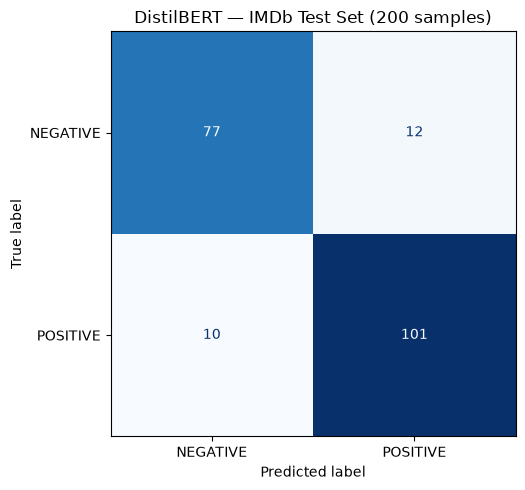

EX2_RESULTS_SAVED_OK
Output directory: D:\learn_DeepLearning\Lab3\outputs\exercise2
 - classification_report.txt
 - confusion_matrix.csv
 - confusion_matrix.png
 - sample_predictions.csv
 - test_metrics.json
 - test_predictions.csv


In [23]:
# EX2 — Save evaluation results and sample predictions

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

output_dir = Path("./outputs/exercise2")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Lưu metrics trên tập test
metrics = {
    "test_samples": int(len(y_true)),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision_positive": float(
        precision_score(y_true, y_pred, zero_division=0)
    ),
    "recall_positive": float(
        recall_score(y_true, y_pred, zero_division=0)
    ),
    "f1_positive": float(
        f1_score(y_true, y_pred, zero_division=0)
    ),
    "best_checkpoint": str(trainer.state.best_model_checkpoint),
}

with (output_dir / "test_metrics.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)

# 2. Lưu classification report
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NEGATIVE", "POSITIVE"],
    digits=4,
    zero_division=0,
)

(output_dir / "classification_report.txt").write_text(
    report, encoding="utf-8"
)

# 3. Lưu confusion matrix dạng CSV và ảnh
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

pd.DataFrame(
    cm,
    index=["Actual_NEGATIVE", "Actual_POSITIVE"],
    columns=["Predicted_NEGATIVE", "Predicted_POSITIVE"],
).to_csv(output_dir / "confusion_matrix.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NEGATIVE", "POSITIVE"],
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("DistilBERT — IMDb Test Set (200 samples)")
fig.tight_layout()
fig.savefig(
    output_dir / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# 4. Lưu nhãn thật và nhãn dự đoán của từng mẫu test
assert len(test_dataset) == len(y_true) == len(y_pred)

pd.DataFrame({
    "text": test_dataset["text"],
    "true_label": y_true,
    "predicted_label": y_pred,
    "correct": y_true == y_pred,
}).to_csv(
    output_dir / "test_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)

# 5. Lưu dự đoán của 4 câu mới
sample_results = [
    predict_sentiment(sentence)
    for sentence in test_sentences
]

pd.DataFrame(sample_results).to_csv(
    output_dir / "sample_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)

print("EX2_RESULTS_SAVED_OK")
print("Output directory:", output_dir.resolve())

for path in sorted(output_dir.iterdir()):
    print(" -", path.name)

In [24]:
# EX2 — Export the best model and tokenizer

from pathlib import Path
import json

model_dir = Path("./outputs/exercise2/final_model")
model_dir.mkdir(parents=True, exist_ok=True)

# Gán tên nhãn rõ ràng
best_model.config.id2label = {
    0: "NEGATIVE",
    1: "POSITIVE",
}
best_model.config.label2id = {
    "NEGATIVE": 0,
    "POSITIVE": 1,
}

# Lưu trọng số và cấu hình của mô hình đã đánh giá
best_model.save_pretrained(
    model_dir,
    safe_serialization=True,
)
tokenizer.save_pretrained(model_dir)

# Lưu cấu hình tiền xử lý dùng khi dự đoán
with (model_dir / "inference_settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        {"max_length": 256, "truncation": True},
        file,
        indent=2,
    )

assert (model_dir / "config.json").exists()
assert (model_dir / "model.safetensors").exists()
assert (model_dir / "tokenizer_config.json").exists()

print("MODEL_EXPORT_OK")
print("Saved to:", model_dir.resolve())

for path in sorted(model_dir.iterdir()):
    print(" -", path.name)

MODEL_EXPORT_OK
Saved to: D:\learn_DeepLearning\Lab3\outputs\exercise2\final_model
 - config.json
 - inference_settings.json
 - model.safetensors
 - special_tokens_map.json
 - tokenizer.json
 - tokenizer_config.json
 - vocab.txt


## Final Results and Conclusion

### Experimental setup
- Pretrained model: DistilBERT (`distilbert-base-uncased`).
- Dataset: IMDb binary sentiment classification.
- Dataset subsets: 1,000 training samples, 200 validation samples,
  and 200 test samples.
- Training duration: 2 epochs (250 optimizer steps).
- Best checkpoint: `checkpoint-125`, selected using validation performance.

### Test results

| Metric | Value |
|---|---:|
| Accuracy | 89.00% |
| Precision (positive class) | 89.38% |
| Recall (positive class) | 90.99% |
| F1-score (positive class) | 90.18% |

The model correctly classified 178 out of 200 test reviews.
It misclassified 12 negative reviews as positive and 10 positive
reviews as negative.

### Observations
Training loss decreased from 0.3781 to 0.1760. However, validation
loss increased from 0.2840 to 0.2998, while validation accuracy
decreased from 90.50% to 89.50%. Therefore, the checkpoint from
epoch 1 was selected for the final evaluation.

The model also produced the expected sentiment labels for four
new example sentences. The exported model and tokenizer were
successfully reloaded in a separate Python process for inference.

### Limitations
The experiment used small subsets of IMDb because of local
hardware constraints. The results describe performance on the
selected 200 test samples and should not be generalized to the
entire dataset or other domains. Input reviews were truncated
to a maximum of 256 tokens during test evaluation and inference.

### Saved outputs
- Evaluation metrics and classification report.
- Confusion matrix in CSV and PNG formats.
- Test predictions and example sentence predictions.
- Exported model and tokenizer in `outputs/exercise2/final_model/`.

### Conclusion
The experiment completed model training, test evaluation,
sentiment prediction, model export, and inference after reloading.
The selected model achieved 89.00% test accuracy and a positive-class
F1-score of 90.18%.